# Dekodowanie

Nagranie + manifest → odpowiedzi impulsowe, 6 metod.

Colab: wgraj caly folder na Dysk, potem

```python
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/colab
```

## 1. Konfiguracja

In [86]:
ZESTAW = "symulacja"

USTAWIENIA = {
    "1sesja":      {"ir_len": 4096,  "offset": "auto"},
    "2sesja_2spk": {"ir_len": 24000, "offset": "auto"},
    "2sesja_4spk": {"ir_len": 24000, "offset": "auto"},
    "symulacja":   {"ir_len": 4096,  "offset": 0},
}

DANE = f"dane/{ZESTAW}"
MANIFEST = f"{DANE}/manifest.json"
RECORDING = f"{DANE}/nagranie.wav"
IR_LEN = USTAWIENIA[ZESTAW]["ir_len"]
TRYB_OFFSETU = USTAWIENIA[ZESTAW]["offset"]
OUT_DIR = f"wyniki/{ZESTAW}"

{"zestaw": ZESTAW, "ir_len": IR_LEN, "offset": TRYB_OFFSETU}

{'zestaw': 'symulacja', 'ir_len': 4096, 'offset': 0}

In [87]:
import json
import os
from dataclasses import dataclass
import numpy as np
import soundfile as sf
from scipy.signal import fftconvolve
import matplotlib.pyplot as plt

## 2. Manifest

In [88]:
with open(MANIFEST, encoding="utf-8") as fh:
    meta = json.load(fh)

N_SPK = meta["speakers"]
FS = meta["fs"]

{k: v for k, v in meta.items() if k != "segments"} | {"segmentow": len(meta["segments"])}

{'speakers': 2,
 'fs': 48000,
 'golay_n': 17,
 'golay_L': 131072,
 'mls_m': 17,
 'mls_L': 131071,
 'mls_reciprocal_L': 131071,
 'gold_m': 16,
 'gold_L': 65535,
 'hadamard_size': 2,
 'guard': 96000,
 'segmentow': 53}

## 3. Nagranie

In [89]:
data, fs_rec = sf.read(RECORDING, always_2d=False)
y = np.asarray(data, dtype=np.float64)
if y.ndim > 1:
    y = y[:, 0]

{"fs": fs_rec, "probek": len(y), "sekund": round(len(y) / FS, 2)}

{'fs': 48000, 'probek': 6210681, 'sekund': 129.39}

## 4. Sekwencje

In [90]:
def golay_pair(n):
    A, B = np.array([1.0]), np.array([1.0])
    for _ in range(n):
        A, B = np.concatenate([A, B]), np.concatenate([A, -B])
    return A, B


def generate_mls(taps, m):
    reg = [1] * m
    seq = []
    for _ in range(2**m - 1):
        seq.append(1.0 if reg[-1] else -1.0)
        fb = 0
        for t in taps:
            fb ^= reg[t - 1]
        reg = [fb] + reg[:-1]
    return np.array(seq)


def bundle_mls(m):
    return generate_mls([17, 14], m)


def reciprocal_mls(seq):
    if len(seq) <= 1:
        return np.array(seq, copy=True)
    return np.concatenate([seq[:1], seq[:0:-1]])


def gold_family(m, n_codes):
    mls1 = generate_mls([16, 14, 13, 11], m)
    mls2 = generate_mls([16, 15, 13, 4], m)
    codes = [mls1, mls2]
    for k in range(len(mls1)):
        if len(codes) >= n_codes:
            break
        codes.append(mls1 * np.roll(mls2, k))
    return codes[:n_codes]


def hadamard_matrix(n):
    H = np.array([[1.0]])
    while H.shape[0] < n:
        H = np.block([[H, H], [H, -H]])
    return H


A, B = golay_pair(meta["golay_n"])
mls = bundle_mls(meta["mls_m"])
H = hadamard_matrix(meta["hadamard_size"])
{"golay_L": A.size, "mls_L": mls.size, "H": H.shape}

{'golay_L': 131072, 'mls_L': 131071, 'H': (2, 2)}

In [91]:
def linear_chirp(fs, dur_s, f0=600.0, f1=6000.0, amp=0.6):
    n = int(round(dur_s * fs))
    t = np.arange(n, dtype=float) / fs
    k = (f1 - f0) / max(dur_s, 1e-12)
    sig = amp * np.sin(2.0 * np.pi * (f0 * t + 0.5 * k * t * t))
    fade = int(min(n // 10, fs * 0.005))
    if fade > 0:
        ramp = np.linspace(0.0, 1.0, fade)
        sig[:fade] *= ramp
        sig[-fade:] *= ramp[::-1]
    return sig


def find_offset(y, meta, fs):
    syncs = [s for s in meta["segments"] if s["kind"] == "sync"]
    ref = linear_chirp(fs, (syncs[0]["end"] - syncs[0]["start"]) / fs)
    margin = 2 * fs
    offsets = []
    for sync in syncs:
        expected = sync["start"]
        lo = max(0, expected - margin)
        hi = min(len(y), expected + margin + ref.size)
        if hi - lo < ref.size:
            continue
        corr = fftconvolve(y[lo:hi], ref[::-1], mode="valid")
        offsets.append(lo + int(np.argmax(np.abs(corr))) - expected)
    return int(np.median(offsets)) if offsets else 0


OFFSET = find_offset(y, meta, FS) if TRYB_OFFSETU == "auto" else int(TRYB_OFFSETU)
for seg in meta["segments"]:
    seg["start"] += OFFSET
    seg["end"] += OFFSET

{"offset": OFFSET, "ms": round(OFFSET / FS * 1000, 1)}

{'offset': 0, 'ms': 0.0}

## 5. Dekodery

In [92]:
def xcorr(y, ref, ir_len):
    c = fftconvolve(y, ref[::-1], mode="full")
    return c[len(ref) - 1:len(ref) - 1 + ir_len]


def decode_solo_golay(y, meta, ir_len):
    L = meta["golay_L"]
    segs = meta["segments"]
    irs = []
    for j in range(meta["speakers"]):
        sa = next(s for s in segs if s["name"] == f"solo_golay_spk{j+1}_A")
        sb = next(s for s in segs if s["name"] == f"solo_golay_spk{j+1}_B")
        ya = y[sa["start"]:sa["start"] + L + ir_len]
        yb = y[sb["start"]:sb["start"] + L + ir_len]
        irs.append((xcorr(ya, A, ir_len) + xcorr(yb, B, ir_len)) / (2.0 * L))
    return irs


def decode_solo_mls(y, meta, ir_len):
    L = meta["mls_L"]
    segs = meta["segments"]
    irs = []
    for j in range(meta["speakers"]):
        seg = next(s for s in segs if s["name"] == f"solo_mls_spk{j+1}")
        yy = y[seg["start"]:seg["start"] + L + ir_len]
        irs.append(xcorr(yy, mls, ir_len) / L)
    return irs


def decode_golay_hadamard(y, meta, ir_len):
    h = meta["hadamard_size"]
    L = meta["golay_L"]
    segs = meta["segments"]
    rows = []
    for i in range(h):
        sa = next(s for s in segs if s["name"] == f"golay_had_row{i+1}_A")
        sb = next(s for s in segs if s["name"] == f"golay_had_row{i+1}_B")
        ya = y[sa["start"]:sa["start"] + L + ir_len]
        yb = y[sb["start"]:sb["start"] + L + ir_len]
        rows.append(xcorr(ya, A, ir_len) + xcorr(yb, B, ir_len))
    decoded = H.T @ np.array(rows)
    return list(decoded[:meta["speakers"]] / (2.0 * L * h))


def decode_mls_hadamard(y, meta, ir_len):
    h = meta["hadamard_size"]
    L = meta["mls_L"]
    segs = meta["segments"]
    rows = []
    for i in range(h):
        seg = next(s for s in segs if s["name"] == f"mls_had_row{i+1}")
        yy = y[seg["start"]:seg["start"] + L + ir_len]
        rows.append(xcorr(yy, mls, ir_len))
    decoded = H.T @ np.array(rows)
    return list(decoded[:meta["speakers"]] / (L * h))


def decode_mls_reciprocal(y, meta, ir_len):
    L = meta["mls_L"]
    seg = next(s for s in meta["segments"] if s["name"] == "mls_reciprocal_pair")
    yy = y[seg["start"]:seg["start"] + L + ir_len]
    return [xcorr(yy, c, ir_len) / L for c in (mls, reciprocal_mls(mls))]


def decode_gold(y, meta, ir_len):
    n = meta["speakers"]
    codes = gold_family(meta["gold_m"], n)
    L = meta["gold_L"]
    seg = next(s for s in meta["segments"] if s["name"] == "gold_all")
    yy = y[seg["start"]:seg["start"] + L + ir_len]
    return [xcorr(yy, codes[j], ir_len) / L for j in range(n)]


[f.__name__ for f in (decode_solo_golay, decode_solo_mls, decode_golay_hadamard,
                      decode_mls_hadamard, decode_mls_reciprocal, decode_gold)]

['decode_solo_golay',
 'decode_solo_mls',
 'decode_golay_hadamard',
 'decode_mls_hadamard',
 'decode_mls_reciprocal',
 'decode_gold']

## 6. Tabela metod

In [93]:
@dataclass(frozen=True)
class Method:
    key: str
    label: str
    decode: object
    color: str


METHODS = [
    Method("solo_golay", "Solo Golay", decode_solo_golay, "#1f77b4"),
    Method("golay_hadamard", "Golay+Hadamard", decode_golay_hadamard, "#2ca02c"),
    Method("solo_mls", "Solo MLS", decode_solo_mls, "#ff7f0e"),
    Method("mls_hadamard", "MLS+Hadamard", decode_mls_hadamard, "#d62728"),
    Method("mls_reciprocal", "MLS reciprocal", decode_mls_reciprocal, "#17becf"),
    Method("gold", "Gold", decode_gold, "#9467bd"),
]

METHOD = {m.key: m for m in METHODS}
[m.key for m in METHODS]

['solo_golay',
 'golay_hadamard',
 'solo_mls',
 'mls_hadamard',
 'mls_reciprocal',
 'gold']

## 7. Dekodowanie

In [94]:
nazwy = {s["name"] for s in meta["segments"]}
dostepne = [m for m in METHODS
            if m.key != "mls_reciprocal" or "mls_reciprocal_pair" in nazwy]

all_decoded = {m.key: m.decode(y, meta, IR_LEN) for m in dostepne}
{k: (len(v), v[0].size) for k, v in all_decoded.items()}
{f"{k}_spk{j+1}": round(float(np.sqrt(np.mean(ir**2))), 8)
 for k, irs in all_decoded.items() for j, ir in enumerate(irs)}

{'solo_golay_spk1': 0.00324556,
 'solo_golay_spk2': 0.00151775,
 'golay_hadamard_spk1': 0.00324556,
 'golay_hadamard_spk2': 0.00151774,
 'solo_mls_spk1': 0.00324649,
 'solo_mls_spk2': 0.00151818,
 'mls_hadamard_spk1': 0.00324649,
 'mls_hadamard_spk2': 0.00151819,
 'mls_reciprocal_spk1': 0.00325372,
 'mls_reciprocal_spk2': 0.00160892,
 'gold_spk1': 0.0032684,
 'gold_spk2': 0.00172369}

## 8. Zapis

In [95]:
os.makedirs(OUT_DIR, exist_ok=True)
for key, irs in all_decoded.items():
    for j, ir in enumerate(irs):
        np.save(os.path.join(OUT_DIR, f"decoded_{key}_spk{j+1}.npy"), ir)

sorted(os.listdir(OUT_DIR))

['decoded_golay_hadamard_spk1.npy',
 'decoded_golay_hadamard_spk2.npy',
 'decoded_gold_spk1.npy',
 'decoded_gold_spk2.npy',
 'decoded_mls_hadamard_spk1.npy',
 'decoded_mls_hadamard_spk2.npy',
 'decoded_mls_reciprocal_spk1.npy',
 'decoded_mls_reciprocal_spk2.npy',
 'decoded_solo_golay_spk1.npy',
 'decoded_solo_golay_spk2.npy',
 'decoded_solo_mls_spk1.npy',
 'decoded_solo_mls_spk2.npy']

## 9. Charakterystyki częstotliwościowe

In [96]:
FMAX_HZ = 20000.0
FMIN_PLOT_HZ = 60.0


def compute_fft_mag_db(ir, fs, fmax=FMAX_HZ):
    x = np.asarray(ir, dtype=float)
    X = np.fft.rfft(x * np.hanning(x.size))
    mag_db = 20.0 * np.log10(np.maximum(np.abs(X), 1e-12))
    f = np.fft.rfftfreq(x.size, d=1.0 / fs)
    m = f <= float(fmax)
    return f[m], mag_db[m]


def smooth_oct(f, y, fraction=3, fmin=20.0):
    f, y = np.asarray(f, dtype=float), np.asarray(y, dtype=float)
    out = y.copy()
    m = f >= fmin
    i0 = int(np.argmax(m))
    lf = np.log2(f[i0:])
    hb = 1.0 / (2.0 * fraction)
    for k in range(lf.size):
        lo = int(np.searchsorted(lf, lf[k] - hb, side="left"))
        hi = int(np.searchsorted(lf, lf[k] + hb, side="right"))
        if hi > lo:
            out[i0 + k] = float(np.mean(y[i0 + lo:i0 + hi]))
    return out


f_demo, _ = compute_fft_mag_db(all_decoded["solo_golay"][0], FS)

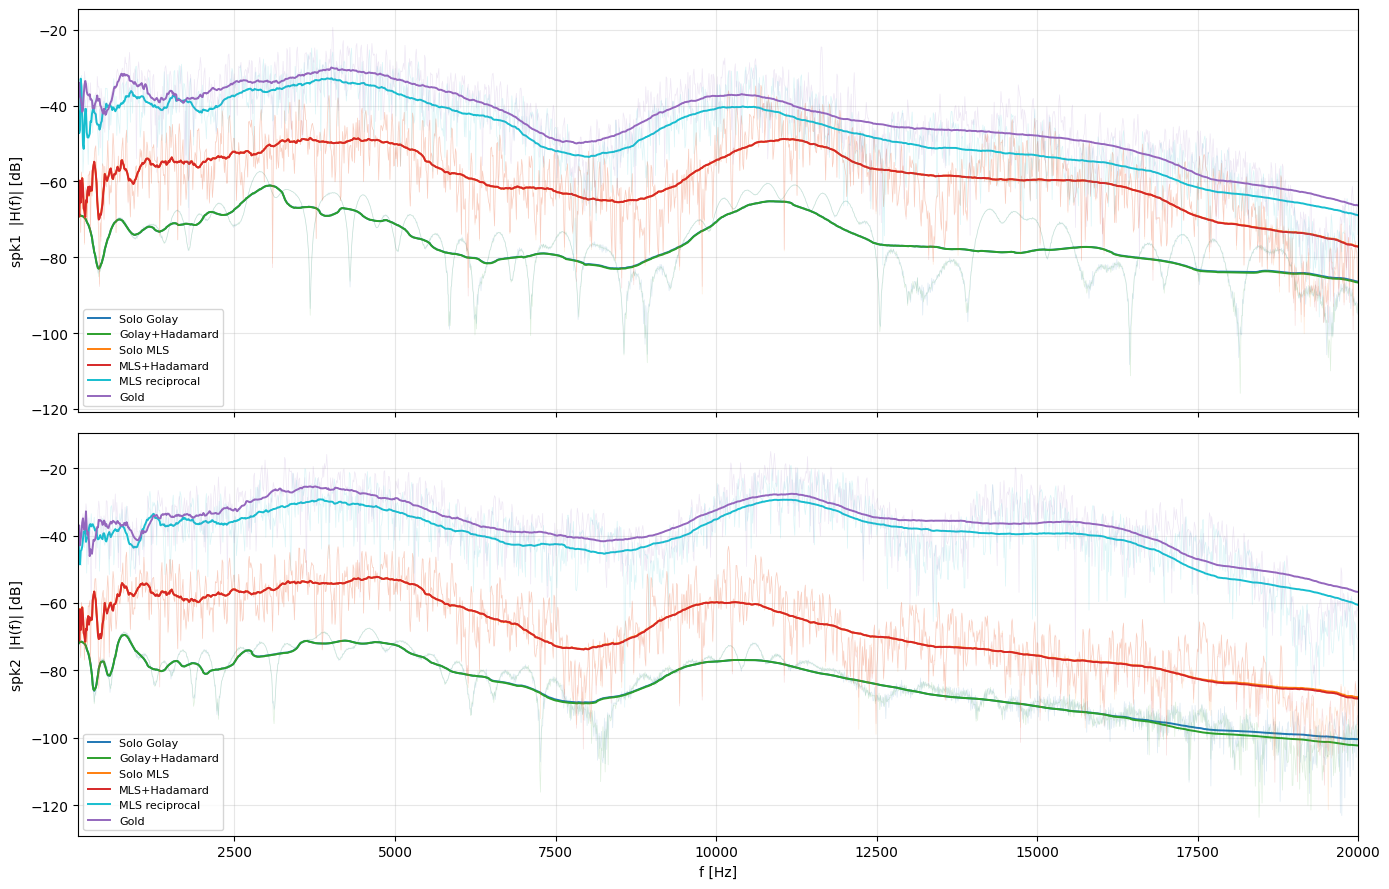

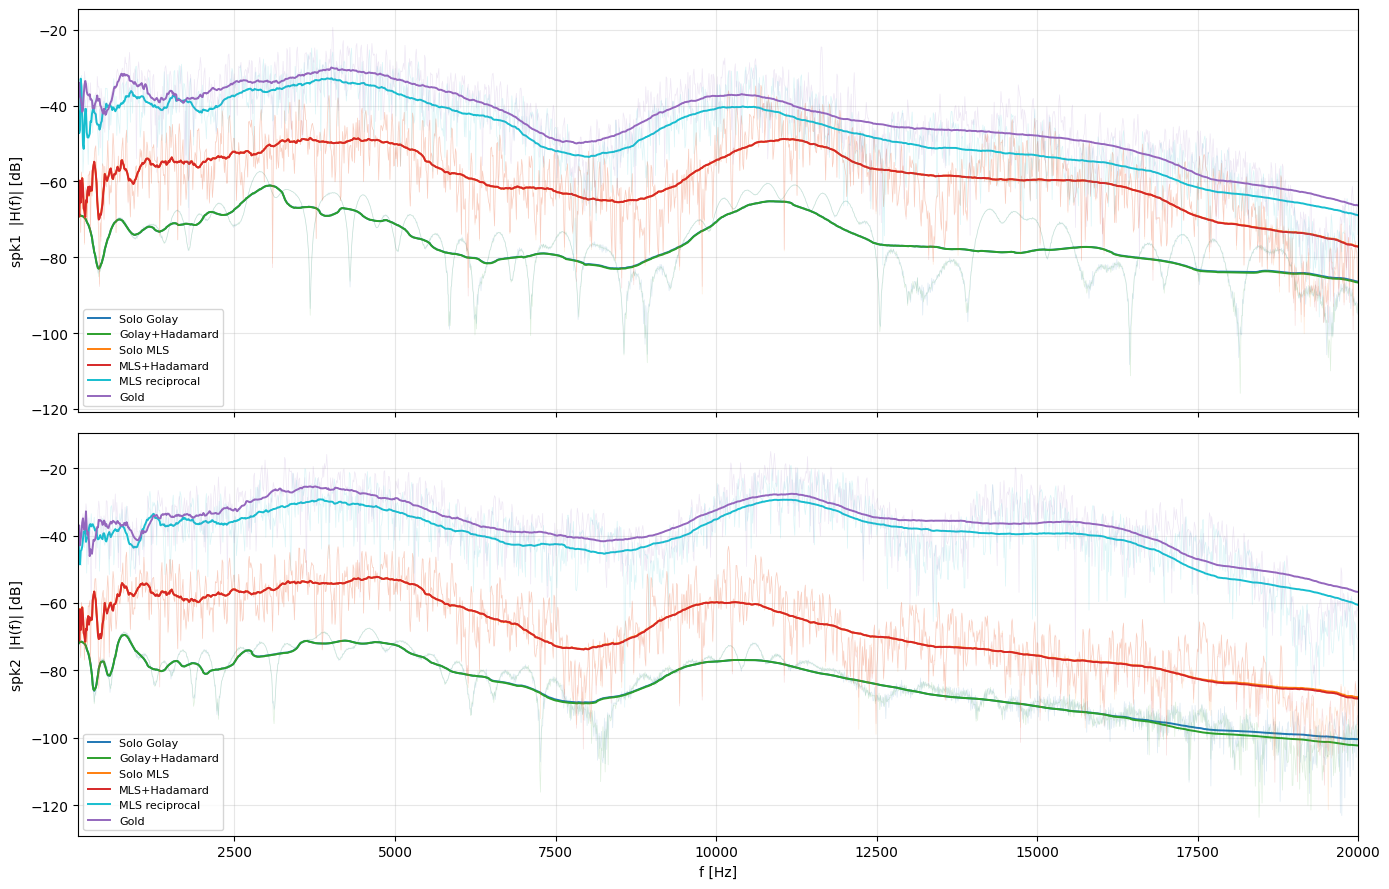

In [97]:
fig, axes = plt.subplots(N_SPK, 1, figsize=(14, 3 + 3 * N_SPK), squeeze=False, sharex=True)
for j in range(N_SPK):
    ax = axes[j][0]
    for key, irs in all_decoded.items():
        m = METHOD[key]
        f, mag = compute_fft_mag_db(irs[j], FS)
        ax.plot(f, mag, color=m.color, alpha=0.15, lw=0.5)
        ax.plot(f, smooth_oct(f, mag), color=m.color, lw=1.4, label=m.label)
    ax.set_ylabel(f"spk{j+1}  |H(f)| [dB]")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc="lower left")

axes[-1][0].set_xlabel("f [Hz]")
axes[-1][0].set_xlim(FMIN_PLOT_HZ, FMAX_HZ)
fig.tight_layout()
fig